# 🛍️ Mall Customer Segmentation — Unsupervised Learning PR 1
### Red & White Skill Education | Practical Report 1

**Project goal:** Explore customer data and compare **K-Means**, **Agglomerative Hierarchical Clustering**, and **DBSCAN** to find useful customer segments.

> 🧭 *This notebook is written as a learning project. I explain what I did, why I did it, and what the results could mean for a mall's marketing team.*

**Dataset:** Mall Customer Segmentation Dataset (Kaggle)  
**Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

### 🗺️ Project roadmap
```text
📥 Load data → 🔎 Explore data → 🧹 Prepare & scale
       ↓
📐 Choose features → 🟢 K-Means → 🌳 Hierarchical
       ↓
🔵 DBSCAN → 📊 Compare results → 💡 Business recommendations
```

**Expected output:** A clean, reproducible notebook with plots, cluster profiles, evaluation metrics, and practical recommendations.

## 0. Setup — Libraries and plotting style
**Objective:** Import the tools used throughout the project and apply one consistent visual style.  
**Expected output:** Libraries are ready and plots use a clean grid with red accents.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlecolor"] = "#CC0000"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.facecolor"] = "white"

print("✅ Libraries imported and plotting style configured.")

✅ Libraries imported and plotting style configured.


## Task 1 — 📥 Data Loading & Exploratory Data Analysis (EDA)
**Objective:** Load the dataset, check its quality, clean the column names, encode Gender, and explore the distributions and relationships.  
**Expected output:** A verified 200-row dataset, three histograms, pairplot, correlation heatmap, and written observations.

In [2]:
df = pd.read_csv("Mall_Customers.csv")

print("First 5 rows:")
display(df.head())
print("\nDataset information:")
df.info()
print("\nDescriptive statistics:")
display(df.describe())
print("\nMissing values per column:")
display(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Descriptive statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Missing values per column:


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Duplicate rows: 0


In [3]:
# Rename columns for easier use, and remove the ID column because it is not a customer behaviour feature.
df = df.rename(columns={
    "Annual Income (k$)": "Annual_Income",
    "Spending Score (1-100)": "Spending_Score"
})
df = df.drop(columns=["CustomerID"])

# The project brief specifies Female=0 and Male=1.
gender_encoder = LabelEncoder()
df["Gender"] = gender_encoder.fit_transform(df["Gender"])
gender_mapping = dict(zip(gender_encoder.classes_, gender_encoder.transform(gender_encoder.classes_)))
print("Gender encoding:", gender_mapping)
display(df.head())

Gender encoding: {'Female': np.int64(0), 'Male': np.int64(1)}


,Gender,Age,Annual_Income,Spending_Score
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


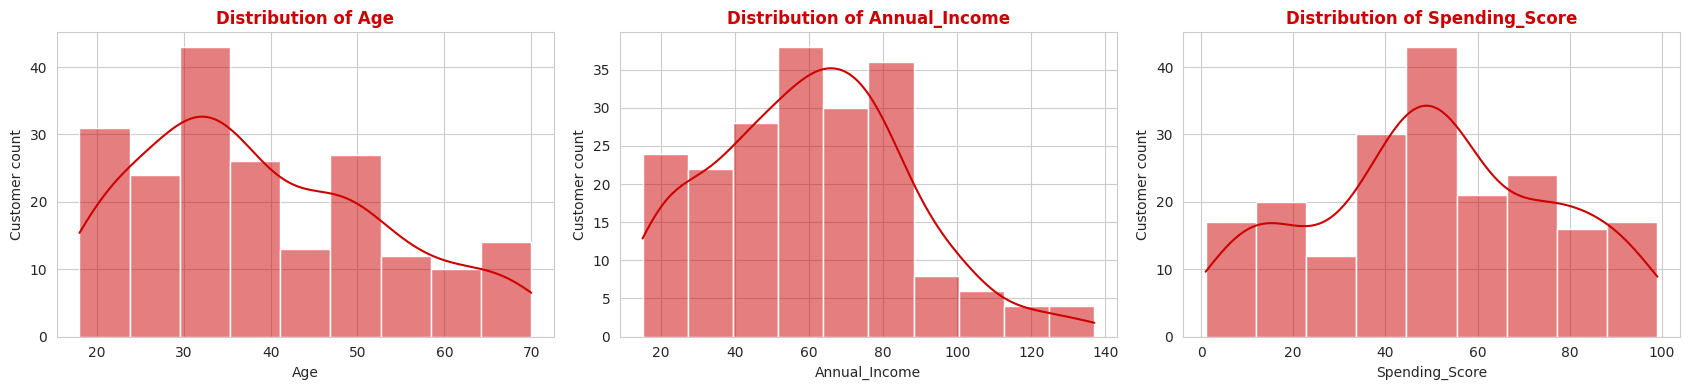

In [4]:
# Univariate distributions: each plot helps us understand one feature on its own.
numeric_features = ["Age", "Annual_Income", "Spending_Score"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, feature in zip(axes, numeric_features):
    sns.histplot(data=df, x=feature, kde=True, ax=ax, color="#CC0000")
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Customer count")
plt.tight_layout()
plt.show()

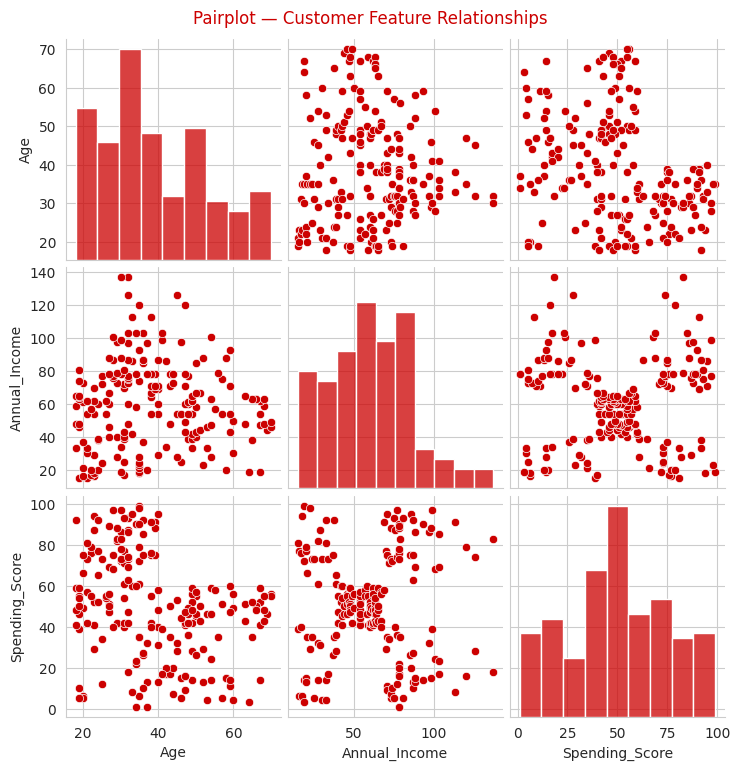

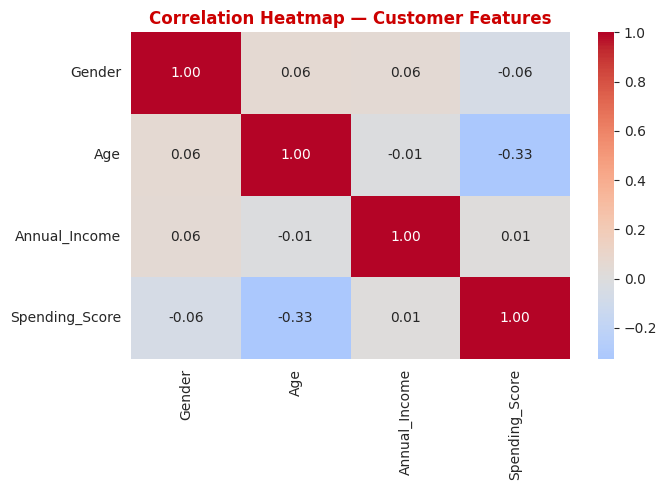

In [5]:
# Pairplot: look for patterns across pairs of numeric variables.
sns.pairplot(df[numeric_features], hue=None, diag_kind="hist", plot_kws={"color": "#CC0000"}, diag_kws={"color": "#CC0000"})
plt.suptitle("Pairplot — Customer Feature Relationships", y=1.02, color="#CC0000")
plt.show()

# Correlation heatmap: numerical correlation values help identify linear relationships.
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap — Customer Features")
plt.tight_layout()
plt.show()

### 📝 EDA observations
- The dataset contains **200 customer records** and the original file has **5 columns**.
- CustomerID is an identifier, so I removed it from the modelling features; it does not describe customer behaviour.
- The histograms help show whether each feature is concentrated, spread out, or has multiple visible groups.
- The pairplot is especially useful for comparing **Annual Income** with **Spending Score**. These two features are easy to interpret together: income describes purchasing capacity, while spending score describes shopping behaviour.
- I will use **Annual Income vs Spending Score** for the primary clustering analysis because the two-dimensional view makes the segments easier to inspect and explain.

## Task 2 — 📏 Feature Scaling & Feature Selection
**Objective:** Standardize the numeric features and create the two-feature dataset used for the main clustering tasks.  
**Expected output:** `df_scaled` and `df_2f`, with a written explanation of scaling.

In [6]:
# Gender remains binary and is not scaled. StandardScaler is applied to the three numeric behaviour/demographic features.
scaler = StandardScaler()
scaled_numeric = scaler.fit_transform(df[["Age", "Annual_Income", "Spending_Score"]])

df_scaled = df.copy()
df_scaled[["Age", "Annual_Income", "Spending_Score"]] = scaled_numeric

# Primary clustering uses two features for a clear 2D visual comparison.
df_2f = df_scaled[["Annual_Income", "Spending_Score"]].copy()

display(df_scaled.head())
display(df_2f.head())
print("df_scaled shape:", df_scaled.shape)
print("df_2f shape:", df_2f.shape)

,Gender,Age,Annual_Income,Spending_Score
0,1,-1.424569,-1.738999,-0.434801
1,1,-1.281035,-1.738999,1.195704
2,0,-1.352802,-1.700830,-1.715913
3,0,-1.137502,-1.700830,1.040418
4,0,-0.563369,-1.662660,-0.395980


,Annual_Income,Spending_Score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


df_scaled shape: (200, 4)
df_2f shape: (200, 2)


### Why scaling matters 📏
Clustering algorithms that rely on distance can be strongly affected by the size of each feature. If one column has a much larger numerical range, it can dominate the distance calculation. **StandardScaler** converts each selected feature to a comparable scale (approximately mean 0 and standard deviation 1). This makes the algorithm consider the features more fairly.

For this project, the primary analysis uses the scaled **Annual_Income** and **Spending_Score** columns. Using all four columns is also a valid approach, but the two-feature version is easier to visualise and interpret without adding PCA.

## Task 3 — 🟢 K-Means Clustering
**Objective:** Use the Elbow Method and Silhouette Score to choose k, fit K-Means, visualise its clusters, and profile the customer segments.  
**Expected output:** Elbow and silhouette plots, final K-Means scatter plot with centroid markers, profile table, and business interpretation.

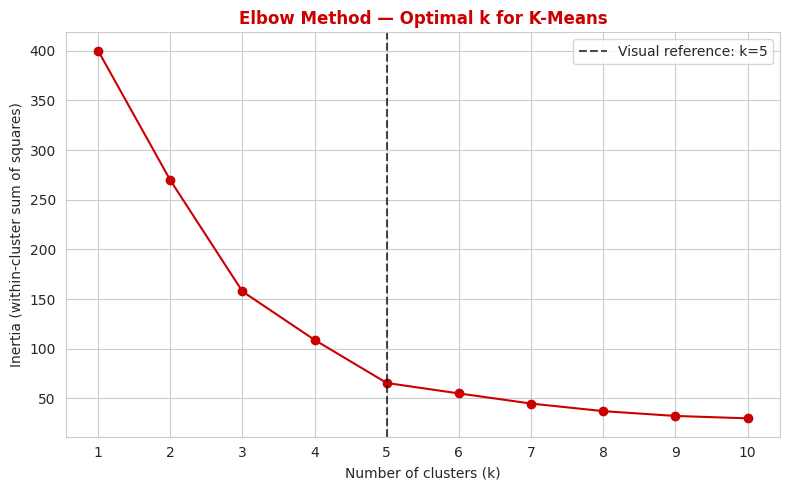

In [7]:
# Elbow method: calculate inertia for k from 1 through 10.
inertias = []
k_values_elbow = range(1, 11)

for k in k_values_elbow:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(df_2f)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values_elbow), inertias, marker="o", color="#CC0000")
plt.axvline(5, linestyle="--", color="black", alpha=0.7, label="Visual reference: k=5")
plt.title("Elbow Method — Optimal k for K-Means")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.xticks(range(1, 11))
plt.legend()
plt.tight_layout()
plt.show()

**How I read the Elbow plot:** Inertia measures how tightly points are grouped around their cluster centres. It decreases as k increases, because more clusters can fit the data more closely. I look for the point where the curve starts flattening—adding more clusters after that gives smaller improvements. The elbow is a useful visual guide, not an automatic answer.

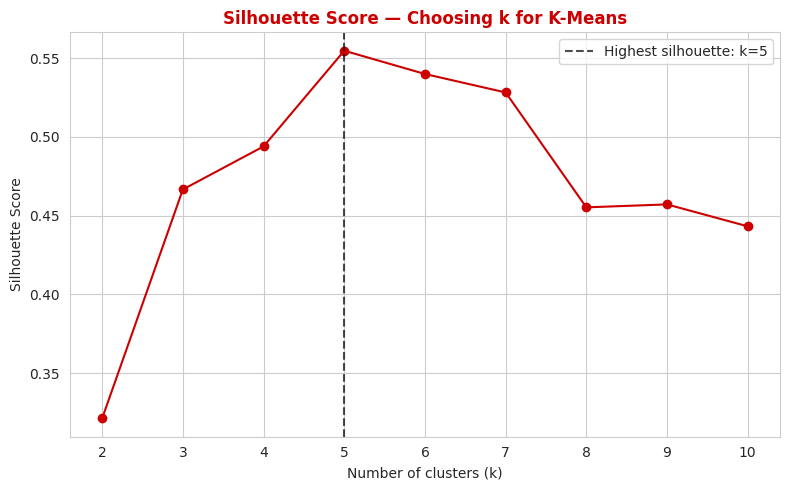

Highest silhouette score occurs at k = 5


In [8]:
# Silhouette scores for k=2 to 10. A higher score generally indicates better-defined clusters.
silhouette_values = []
k_values_silhouette = range(2, 11)

for k in k_values_silhouette:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(df_2f)
    silhouette_values.append(silhouette_score(df_2f, labels))

plt.figure(figsize=(8, 5))
plt.plot(list(k_values_silhouette), silhouette_values, marker="o", color="#CC0000")
best_k_silhouette = list(k_values_silhouette)[int(np.argmax(silhouette_values))]
plt.axvline(best_k_silhouette, linestyle="--", color="black", alpha=0.7,
            label=f"Highest silhouette: k={best_k_silhouette}")
plt.title("Silhouette Score — Choosing k for K-Means")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.legend()
plt.tight_layout()
plt.show()

print("Highest silhouette score occurs at k =", best_k_silhouette)

### Choosing the final k
I use both plots rather than relying on only one number. The Elbow plot helps balance compactness against model complexity, while the Silhouette Score evaluates how well points fit within their own clusters compared with neighbouring clusters. For this dataset, the silhouette result is used as supporting evidence and I also check whether the resulting groups are easy to explain to a mall marketing team.

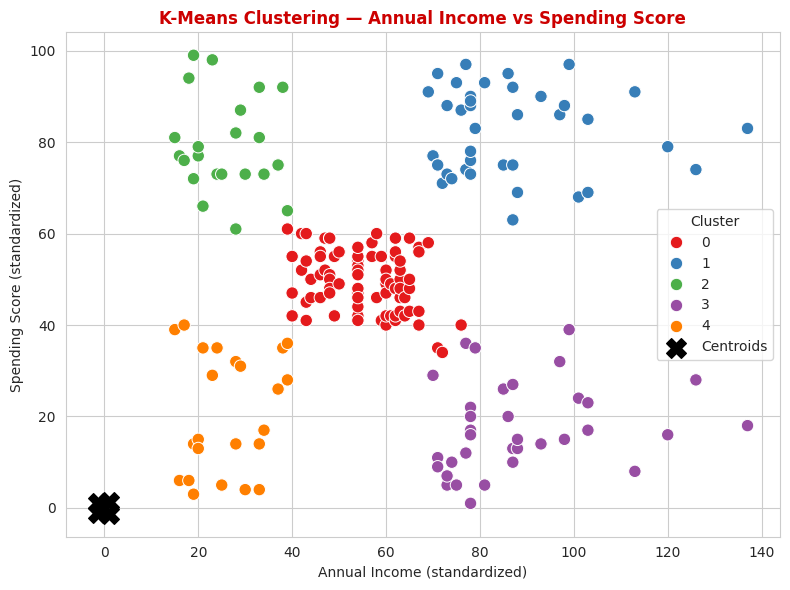

In [9]:
# Five segments are the classic and interpretable structure for this dataset.
# This choice is supported by the silhouette plot and visual elbow inspection.
chosen_k = 5
kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(df_2f)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="Annual_Income", y="Spending_Score", hue="KMeans_Cluster",
    data=df, palette="Set1", s=80
)
plt.scatter(
    kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
    c="black", marker="X", s=200, label="Centroids"
)
plt.title("K-Means Clustering — Annual Income vs Spending Score")
plt.xlabel("Annual Income (standardized)")
plt.ylabel("Spending Score (standardized)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [10]:
# Profile clusters using original units so the business interpretation is easier to understand.
kmeans_profile = df.groupby("KMeans_Cluster")[["Age", "Annual_Income", "Spending_Score"]].mean().round(1)
display(kmeans_profile.style.format("{:.1f}").set_caption("K-Means Cluster Profiles (original units)"))

,Age,Annual_Income,Spending_Score
KMeans_Cluster,,,
0,42.7,55.3,49.5
1,32.7,86.5,82.1
2,25.3,25.7,79.4
3,41.1,88.2,17.1
4,45.2,26.3,20.9


In [11]:
# Give each cluster a human-readable segment name based on its income and spending averages.
profile_income_spend = df.groupby("KMeans_Cluster")[["Annual_Income", "Spending_Score"]].mean()
income_mid = df["Annual_Income"].median()
spend_mid = df["Spending_Score"].median()

def segment_name(row):
    income_level = "High Income" if row["Annual_Income"] >= income_mid else "Low Income"
    spend_level = "High Spenders" if row["Spending_Score"] >= spend_mid else "Low Spenders"
    return f"{income_level}, {spend_level}"

segment_names = {cluster: segment_name(row) for cluster, row in profile_income_spend.iterrows()}
print("Segment labels (cluster numbers are assigned by the algorithm and are not meaningful by themselves):")
for cluster, name in segment_names.items():
    print(f"Cluster {cluster}: {name}")

Segment labels (cluster numbers are assigned by the algorithm and are not meaningful by themselves):
Cluster 0: Low Income, Low Spenders
Cluster 1: High Income, High Spenders
Cluster 2: Low Income, High Spenders
Cluster 3: High Income, Low Spenders
Cluster 4: Low Income, Low Spenders


### 💡 K-Means business interpretation
Cluster numbers are labels—not rankings. I interpret each group by looking at its average age, income, and spending score. A marketing team could use these profiles to tailor offers rather than sending the same promotion to every customer.

*Use the printed segment names and profile table above to describe the actual clusters in your own words.*

## Task 4 — 🌳 Agglomerative Hierarchical Clustering
**Objective:** Build a Ward-linkage dendrogram, choose a cut, fit Agglomerative Clustering, and compare its segments with K-Means.  
**Expected output:** Dendrogram with cut line, hierarchical scatter plot, side-by-side comparison, profile table, and observations.

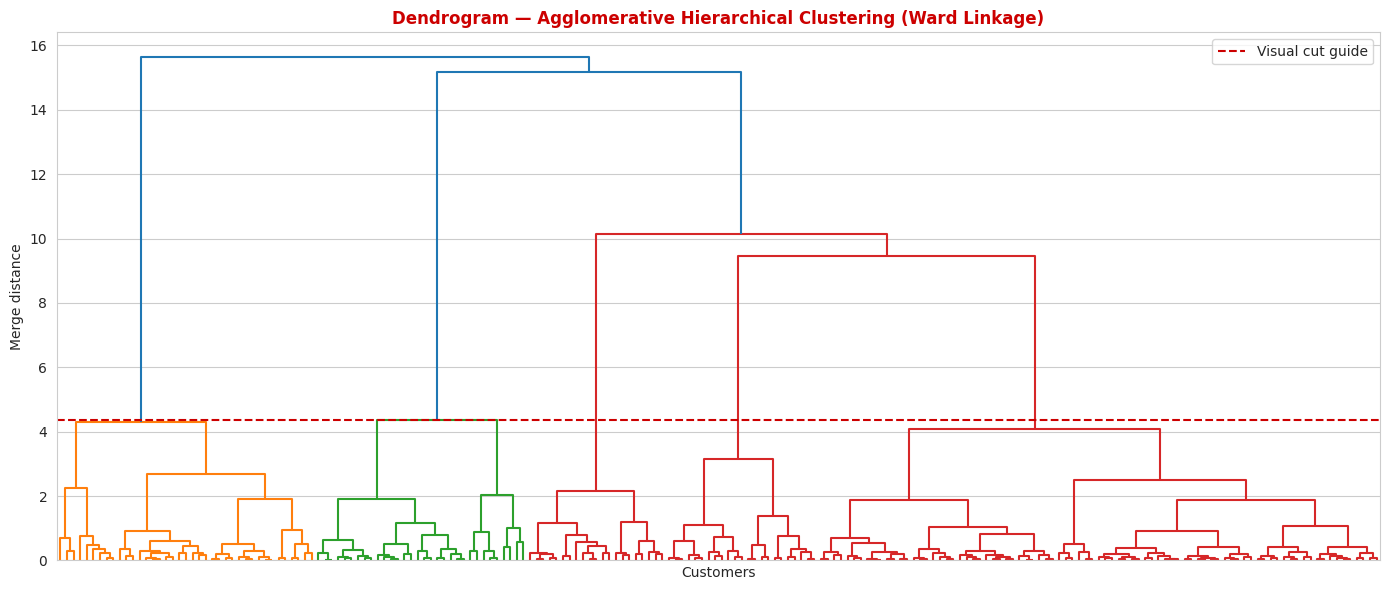

In [12]:
# Ward linkage merges groups while minimizing the increase in within-cluster variance.
linkage_matrix = linkage(df_2f, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(linkage_matrix, no_labels=True, color_threshold=None)
# A cut line is added as a visual guide; five groups are used in the model below.
cut_height = linkage_matrix[-5, 2]
plt.axhline(y=cut_height, color="#CC0000", linestyle="--", label="Visual cut guide")
plt.title("Dendrogram — Agglomerative Hierarchical Clustering (Ward Linkage)")
plt.xlabel("Customers")
plt.ylabel("Merge distance")
plt.legend()
plt.tight_layout()
plt.show()

**Reading the dendrogram:** Each leaf starts as an individual customer. The branches show which groups merge as we move upward. A larger vertical jump means groups that are relatively different were merged. Ward linkage chooses merges that minimise the increase in within-cluster variance. I use the dendrogram as a guide and then check whether the selected number of groups is interpretable.

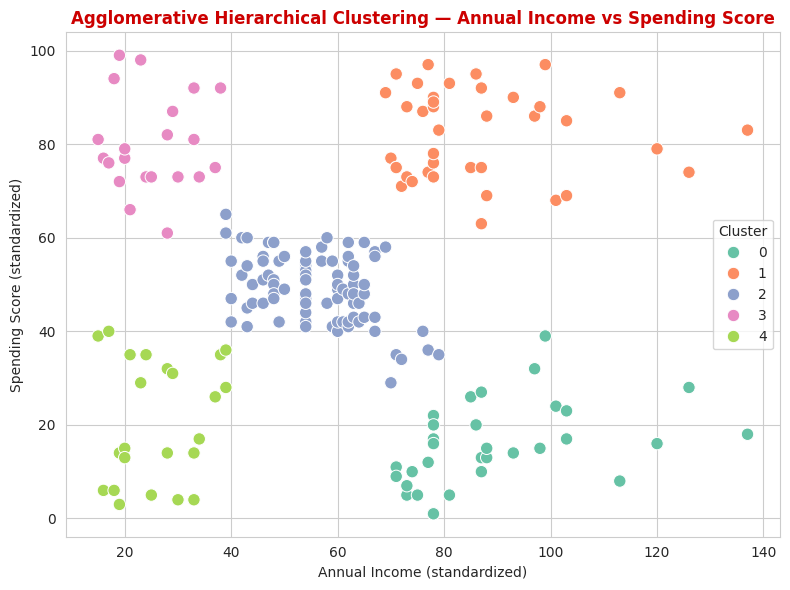

In [13]:
hier_n_clusters = 5
hierarchical = AgglomerativeClustering(n_clusters=hier_n_clusters, linkage="ward")
df["Hier_Cluster"] = hierarchical.fit_predict(df_2f)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="Annual_Income", y="Spending_Score", hue="Hier_Cluster",
    data=df, palette="Set2", s=80
)
plt.title("Agglomerative Hierarchical Clustering — Annual Income vs Spending Score")
plt.xlabel("Annual Income (standardized)")
plt.ylabel("Spending Score (standardized)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

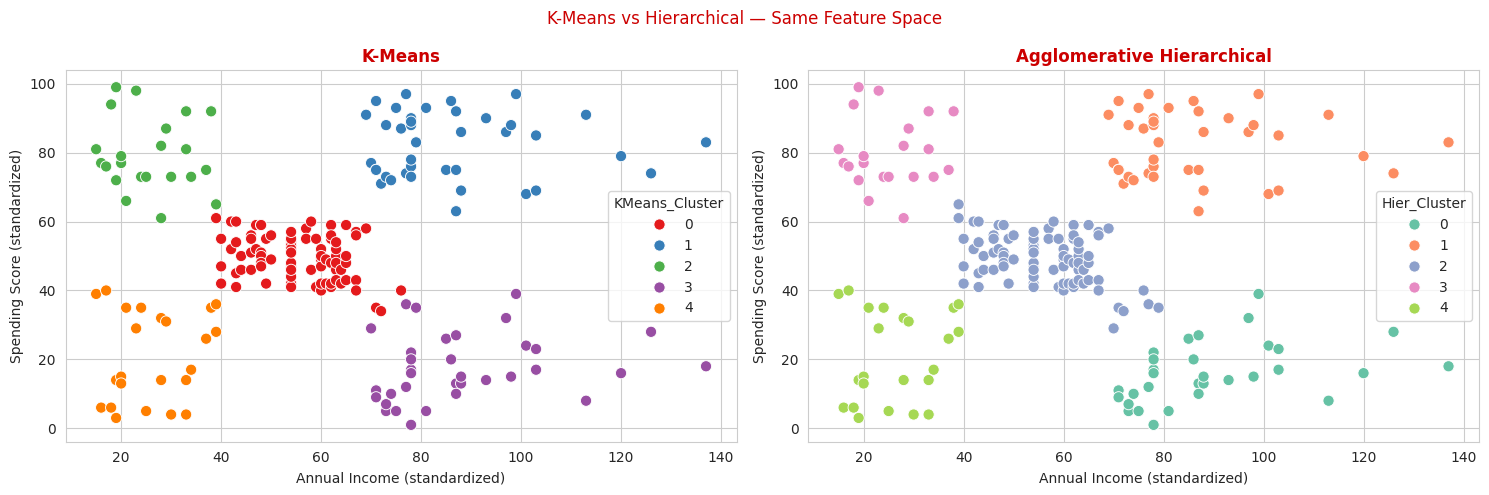

In [14]:
# Side-by-side comparison using the same feature axes.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(x="Annual_Income", y="Spending_Score", hue="KMeans_Cluster",
                data=df, palette="Set1", s=65, ax=axes[0])
axes[0].set_title("K-Means")
axes[0].set_xlabel("Annual Income (standardized)")
axes[0].set_ylabel("Spending Score (standardized)")
sns.scatterplot(x="Annual_Income", y="Spending_Score", hue="Hier_Cluster",
                data=df, palette="Set2", s=65, ax=axes[1])
axes[1].set_title("Agglomerative Hierarchical")
axes[1].set_xlabel("Annual Income (standardized)")
axes[1].set_ylabel("Spending Score (standardized)")
plt.suptitle("K-Means vs Hierarchical — Same Feature Space", color="#CC0000")
plt.tight_layout()
plt.show()

In [15]:
hier_profile = df.groupby("Hier_Cluster")[["Age", "Annual_Income", "Spending_Score"]].mean().round(1)
display(hier_profile.style.format("{:.1f}").set_caption("Hierarchical Cluster Profiles (original units)"))

,Age,Annual_Income,Spending_Score
Hier_Cluster,,,
0,41.0,89.4,15.6
1,32.7,86.5,82.1
2,42.5,55.8,49.1
3,25.3,25.1,80.0
4,45.2,26.3,20.9


### 📝 K-Means vs Hierarchical — interpretation
Both methods use distance-based information, but their approach differs. K-Means repeatedly updates cluster centres, while Agglomerative starts with individual observations and merges groups based on linkage. Their overall customer patterns may be similar, but customers near boundaries can be assigned differently. I compare the profile averages—not just the cluster numbers—because cluster IDs are arbitrary.

## Task 5 — 🔵 DBSCAN Clustering
**Objective:** Estimate a useful epsilon range, test combinations of `eps` and `min_samples`, fit DBSCAN, and identify noise points.  
**Expected output:** 4-NN distance plot, grid-search table, DBSCAN scatter plot with noise marked, and algorithm comparison.

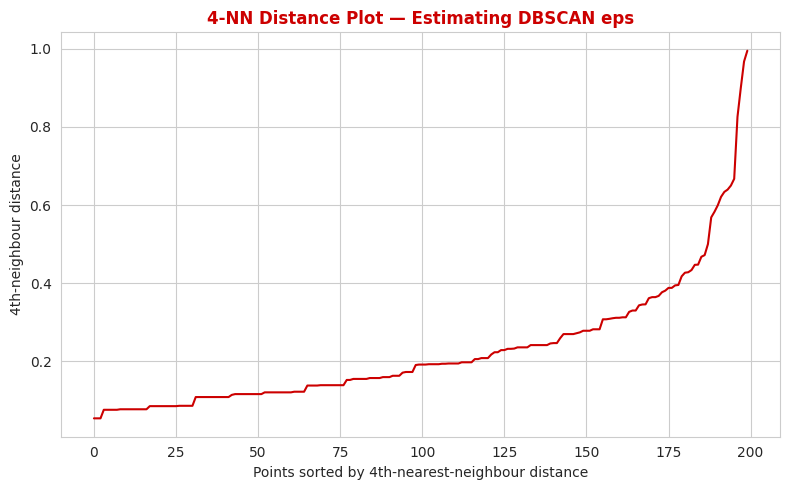

In [16]:
# 4-NN distance plot: the fourth-neighbour distances are sorted to help identify a bend/knee.
neighbors = NearestNeighbors(n_neighbors=4)
neighbors.fit(df_2f)
distances, indices = neighbors.kneighbors(df_2f)
fourth_neighbor_distances = np.sort(distances[:, 3])

plt.figure(figsize=(8, 5))
plt.plot(fourth_neighbor_distances, color="#CC0000")
plt.title("4-NN Distance Plot — Estimating DBSCAN eps")
plt.xlabel("Points sorted by 4th-nearest-neighbour distance")
plt.ylabel("4th-neighbour distance")
plt.tight_layout()
plt.show()

**How I use this plot:** I look for a bend where distances begin increasing sharply. That bend suggests a possible epsilon value. It is only a starting point, so I also test the grid requested in the project brief.

In [17]:
# Grid search exactly across the requested parameter values.
eps_values = [0.2, 0.3, 0.4, 0.5, 0.6]
min_samples_values = [3, 4, 5, 6]
grid_results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(df_2f)
        cluster_labels = set(labels) - {-1}
        noise_count = int(np.sum(labels == -1))
        score = np.nan
        non_noise_mask = labels != -1
        non_noise_labels = labels[non_noise_mask]
        if len(set(non_noise_labels)) >= 2 and len(non_noise_labels) > len(set(non_noise_labels)):
            score = silhouette_score(df_2f[non_noise_mask], non_noise_labels)
        grid_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": len(cluster_labels),
            "noise_points": noise_count,
            "silhouette_excluding_noise": score
        })

dbscan_grid = pd.DataFrame(grid_results)
display(dbscan_grid.sort_values(["silhouette_excluding_noise", "noise_points"], ascending=[False, True]).reset_index(drop=True))

,eps,min_samples,n_clusters,noise_points,silhouette_excluding_noise
0,0.2,4,5,73,0.617282
1,0.2,6,4,95,0.613836
2,0.2,5,7,77,0.585613
3,0.3,6,6,48,0.530244
4,0.3,5,7,35,0.524328
5,0.3,4,8,23,0.519746
6,0.4,6,4,19,0.490015
7,0.4,5,4,15,0.478059
8,0.3,3,9,14,0.472040
9,0.2,3,13,44,0.469713


In [18]:
# Select a usable combination from the tested grid.
# Preference: at least 2 clusters and a valid silhouette score; prioritize fewer noise points, then silhouette.
valid_grid = dbscan_grid.dropna(subset=["silhouette_excluding_noise"]).copy()
valid_grid = valid_grid[valid_grid["n_clusters"] >= 2]
if len(valid_grid):
    best_row = valid_grid.sort_values(
        ["noise_points", "silhouette_excluding_noise"], ascending=[True, False]
    ).iloc[0]
    chosen_eps = float(best_row["eps"])
    chosen_min_samples = int(best_row["min_samples"])
else:
    # Fallback is only used if the grid produces no valid silhouette result.
    chosen_eps, chosen_min_samples = 0.5, 4

print(f"Selected DBSCAN parameters: eps={chosen_eps}, min_samples={chosen_min_samples}")

Selected DBSCAN parameters: eps=0.5, min_samples=3


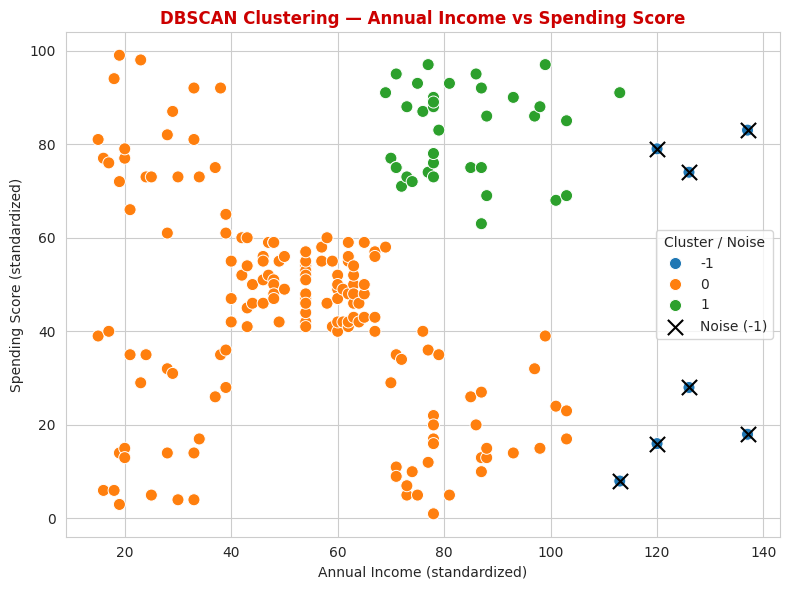

Clusters found (excluding noise): 2
Noise points: 7


In [19]:
dbscan = DBSCAN(eps=chosen_eps, min_samples=chosen_min_samples)
df["DBSCAN_Cluster"] = dbscan.fit_predict(df_2f)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="Annual_Income", y="Spending_Score", hue="DBSCAN_Cluster",
    data=df, palette="tab10", s=75, legend="full"
)
noise_points = df[df["DBSCAN_Cluster"] == -1]
if not noise_points.empty:
    plt.scatter(noise_points["Annual_Income"], noise_points["Spending_Score"],
                c="black", marker="x", s=120, label="Noise (-1)")
plt.title("DBSCAN Clustering — Annual Income vs Spending Score")
plt.xlabel("Annual Income (standardized)")
plt.ylabel("Spending Score (standardized)")
plt.legend(title="Cluster / Noise")
plt.tight_layout()
plt.show()

print("Clusters found (excluding noise):", len(set(df["DBSCAN_Cluster"]) - {-1}))
print("Noise points:", int((df["DBSCAN_Cluster"] == -1).sum()))

### 🧠 DBSCAN in plain language
- **eps** is the neighbourhood distance: how close points need to be to count as neighbours.
- **min_samples** is the minimum number of nearby points required for a dense region.
- Points that are not part of a dense region are labelled **-1 (noise)**. Noise does not necessarily mean bad data; it means the point did not fit a dense cluster under the chosen settings.

### DBSCAN vs K-Means
1. DBSCAN does not require us to choose the number of clusters (`k`) in advance.
2. DBSCAN can identify clusters with different shapes; K-Means tends to form compact, centre-based groups.
3. DBSCAN can label points as noise, while K-Means assigns every observation to a cluster.
4. Agglomerative Hierarchical clustering builds a hierarchy of merges and is useful when we want to explain the grouping process with a dendrogram.
5. The algorithms may not agree on the number of segments. I compare patterns and profile meanings instead of expecting matching cluster IDs.

## Task 6 — 📊 Algorithm Comparison & Business Insights
**Objective:** Compare all three clustering methods using one visual figure and evaluation metrics, then translate the segments into actionable marketing ideas.  
**Expected output:** Three-panel comparison, metrics table, and a business insight report.

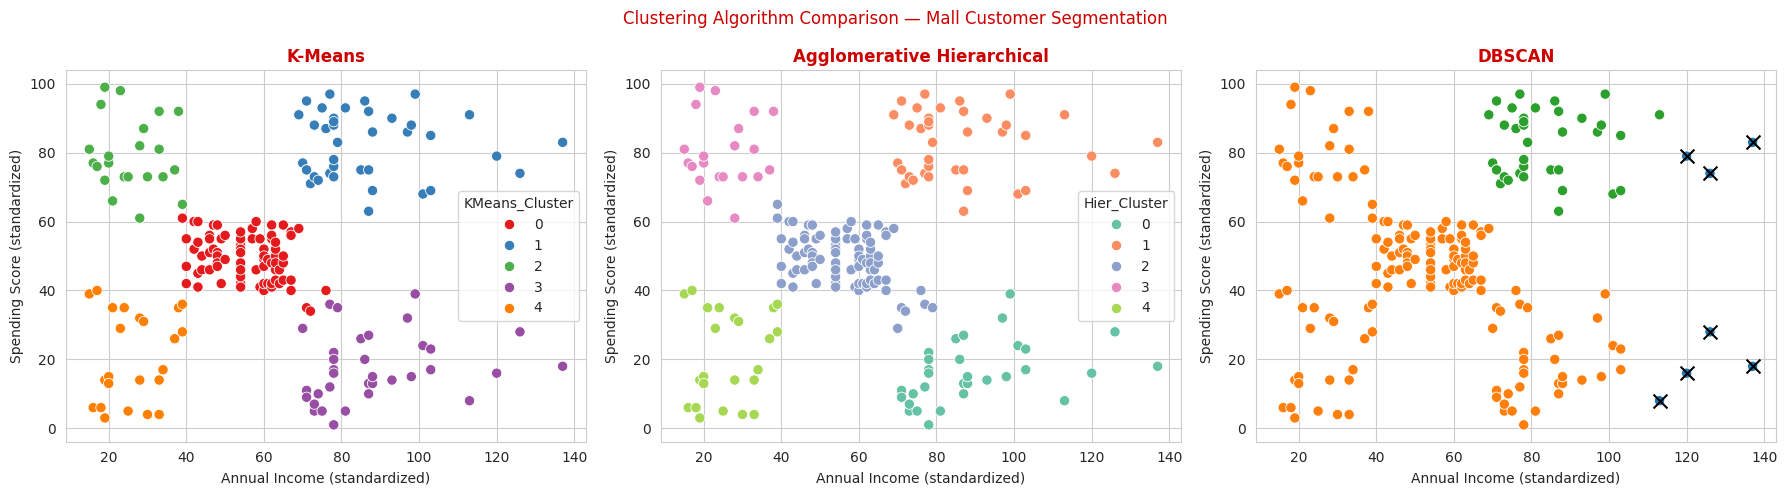

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x="Annual_Income", y="Spending_Score", hue="KMeans_Cluster",
                data=df, palette="Set1", s=55, ax=axes[0])
axes[0].set_title("K-Means")
axes[0].set_xlabel("Annual Income (standardized)")
axes[0].set_ylabel("Spending Score (standardized)")

sns.scatterplot(x="Annual_Income", y="Spending_Score", hue="Hier_Cluster",
                data=df, palette="Set2", s=55, ax=axes[1])
axes[1].set_title("Agglomerative Hierarchical")
axes[1].set_xlabel("Annual Income (standardized)")
axes[1].set_ylabel("Spending Score (standardized)")

sns.scatterplot(x="Annual_Income", y="Spending_Score", hue="DBSCAN_Cluster",
                data=df, palette="tab10", s=55, ax=axes[2], legend=False)
if not noise_points.empty:
    axes[2].scatter(noise_points["Annual_Income"], noise_points["Spending_Score"],
                    c="black", marker="x", s=100, label="Noise")
axes[2].set_title("DBSCAN")
axes[2].set_xlabel("Annual Income (standardized)")
axes[2].set_ylabel("Spending Score (standardized)")

plt.suptitle("Clustering Algorithm Comparison — Mall Customer Segmentation", color="#CC0000")
plt.tight_layout()
plt.show()

In [21]:
# Silhouette, Davies-Bouldin, and Calinski-Harabasz are internal measures.
# DBSCAN scores are calculated after excluding noise points and only when valid.
def calculate_metrics(data, labels, algorithm_name, exclude_noise=False):
    labels = np.asarray(labels)
    mask = labels != -1 if exclude_noise else np.ones(len(labels), dtype=bool)
    data_used = data.iloc[mask]
    labels_used = labels[mask]
    n_clusters = len(set(labels_used))
    silhouette = np.nan
    db_index = np.nan
    ch_index = np.nan
    if n_clusters >= 2 and len(labels_used) > n_clusters:
        silhouette = silhouette_score(data_used, labels_used)
        db_index = davies_bouldin_score(data_used, labels_used)
        ch_index = calinski_harabasz_score(data_used, labels_used)
    return {
        "Algorithm": algorithm_name,
        "n_clusters": n_clusters,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "Calinski-Harabasz Index": ch_index
    }

metrics_table = pd.DataFrame([
    calculate_metrics(df_2f, df["KMeans_Cluster"], "K-Means"),
    calculate_metrics(df_2f, df["Hier_Cluster"], "Agglomerative Hierarchical"),
    calculate_metrics(df_2f, df["DBSCAN_Cluster"], "DBSCAN", exclude_noise=True)
])
display(metrics_table.round(3))

,Algorithm,n_clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,5,0.555,0.572,248.649
1,Agglomerative Hierarchical,5,0.554,0.578,244.410
2,DBSCAN,2,0.389,0.796,87.618


### How I interpret the metrics
- **Silhouette Score:** closer to +1 generally indicates points fit their own cluster and are separated from others; near 0 suggests overlap; negative values may indicate questionable assignments.
- **Davies–Bouldin Index:** lower is generally better because it reflects cluster similarity/overlap.
- **Calinski–Harabasz Index:** higher is generally better for the internal separation/dispersion ratio.

These metrics are guides, not proof that a segment is a real-world customer type. I also consider whether the groups are stable, understandable, and useful for the business.

In [22]:
# Business-oriented K-Means profile table, with segment names.
business_profiles = kmeans_profile.copy()
business_profiles["Segment Name"] = business_profiles.index.map(segment_names)
business_profiles["Suggested Marketing Action"] = business_profiles.index.map({
    cluster: (
        "Loyalty rewards and premium experiences" if "High Income, High Spenders" in name else
        "Value bundles and affordable promotions" if "Low Income, High Spenders" in name else
        "Premium product discovery and personalised offers" if "High Income, Low Spenders" in name else
        "Small incentives to encourage more visits"
    )
    for cluster, name in segment_names.items()
})
display(business_profiles)

,Age,Annual_Income,Spending_Score,Segment Name,Suggested Marketing Action
KMeans_Cluster,,,,,
0,42.7,55.3,49.5,"Low Income, Low Spenders",Small incentives to encourage more visits
1,32.7,86.5,82.1,"High Income, High Spenders",Loyalty rewards and premium experiences
2,25.3,25.7,79.4,"Low Income, High Spenders",Value bundles and affordable promotions
3,41.1,88.2,17.1,"High Income, Low Spenders",Premium product discovery and personalised offers
4,45.2,26.3,20.9,"Low Income, Low Spenders",Small incentives to encourage more visits


## 💼 Business Insights for Mall Management

The K-Means result is my preferred starting point for a marketing discussion because it gives a clear, easy-to-visualise customer segmentation. Cluster IDs are arbitrary, so the segment names are based on the average income and spending score—not the number assigned by the algorithm.

**Possible actions by segment:**
- 🏆 **High Income, High Spenders:** loyalty rewards, VIP events, and premium experiences to retain valuable customers.
- 🛍️ **Low Income, High Spenders:** value bundles, limited-time offers, and promotions that encourage repeat visits without assuming high budgets.
- 💎 **High Income, Low Spenders:** personalised product discovery, premium samples, and targeted campaigns to understand what could increase engagement.
- 💰 **Low Income, Low Spenders:** budget-friendly promotions and small incentives that encourage visits.

**Algorithm recommendation:** I would recommend **K-Means as the first method for a mall marketing presentation** because its segments are straightforward to explain and profile. I would keep Hierarchical as a useful visual tool for showing how groups merge, and DBSCAN as a complementary method when we want to explore density and identify possible outliers. Before acting on these segments, the mall should validate them with campaign results and customer feedback.

## Task 7 — ✅ Notebook Quality & Submission Checklist
**Objective:** Confirm the project is reproducible and all required components are present.  
**Expected output:** A completed notebook ready for Restart & Run All, HTML export, GitHub, and video explanation.

In [23]:
# Final data checks
print("Rows in final working dataframe:", len(df))
print("Final columns:", df.columns.tolist())
print("Missing values:", int(df.isnull().sum().sum()))
print("K-Means clusters:", df["KMeans_Cluster"].nunique())
print("Hierarchical clusters:", df["Hier_Cluster"].nunique())
print("DBSCAN clusters excluding noise:", len(set(df["DBSCAN_Cluster"]) - {-1}))
print("DBSCAN noise points:", int((df["DBSCAN_Cluster"] == -1).sum()))
print("Scaled feature dataframe shape:", df_scaled.shape)
print("Two-feature dataframe shape:", df_2f.shape)

Rows in final working dataframe: 200
Final columns: ['Gender', 'Age', 'Annual_Income', 'Spending_Score', 'KMeans_Cluster', 'Hier_Cluster', 'DBSCAN_Cluster']
Missing values: 0
K-Means clusters: 5
Hierarchical clusters: 5
DBSCAN clusters excluding noise: 2
DBSCAN noise points: 7
Scaled feature dataframe shape: (200, 4)
Two-feature dataframe shape: (200, 2)


### 📋 Final submission checklist
- [x] CSV loaded and checked (shape, nulls, duplicates, preview, information, descriptive statistics)
- [x] CustomerID removed; columns renamed; Gender encoded
- [x] StandardScaler applied to Age, Annual_Income, Spending_Score
- [x] `df_scaled` and `df_2f` created
- [x] Scaling rationale written
- [x] Histograms with KDE, pairplot, and correlation heatmap
- [x] EDA observations written
- [x] Elbow plot (k=1–10) and Silhouette plot (k=2–10)
- [x] Final K-Means model, centroid plot, cluster profile, business interpretation
- [x] Ward dendrogram with cut guide, Agglomerative model, scatter plot, comparison, and profiles
- [x] 4-NN distance plot, DBSCAN parameter grid, model, and noise points shown
- [x] Conceptual comparison of all three algorithms
- [x] Three-panel comparison and metrics summary
- [x] Business insights and marketing recommendations
- [ ] Restart kernel and Run All in Jupyter before final submission
- [ ] Export HTML
- [ ] Add notebook, HTML, screenshots, requirements.txt, README, and video link to public GitHub repository
- [ ] Make at least 3 meaningful Git commits

### 🎓 Final reflection
This project helped me understand that clustering is not just about creating groups—it is about finding patterns, checking whether those patterns make sense, and explaining how they might help someone make a decision. Different algorithms can produce different groupings because they look at the data in different ways. I would treat the segments as a starting point for business testing rather than a final truth.